# Two-Dimensional Vortex Panel Methods
### Constant-strength and linear-strength panels: algorithms, implementation, verification and limits

**Name:** Bala Surya S
**Student ID:** SC26M009
**Course:** AE 611 – Assignment on the 2D Vortex Panel Method

---
**What this notebook does.** It builds two vortex panel solvers from scratch (`vortex_panel_method_0` for constant and `vortex_panel_method_1` for linear vortex strength), checks them against the exact potential flow around a circular cylinder, studies how they converge on a symmetric (NACA 0012) and a cambered (NACA 4412) airfoil, uses them to predict airfoil characteristics, and finally uses them to show *where* the method stops being a reliable predictor (thick airfoils). The notebook runs top to bottom with *Run All*; it needs only `numpy` and `matplotlib` and takes a few seconds.

**Contents**
1. Algorithms
2. Implementation in Python
3. Verification on a circular cylinder
4. Verification on symmetric and non-symmetric airfoils (panel number and panel distribution)
5. Prediction of airfoil characteristics
6. Limitations of the prediction: effect of airfoil thickness
7. Summary, references and acknowledgements

## 1. Algorithms

### 1.1 Model, conventions and the influence of one panel

Steady, incompressible, inviscid, irrotational flow past a body is represented by a vortex sheet of strength $\gamma$ (circulation per unit length) laid on the body surface. The surface is replaced by $N$ straight panels with $N+1$ boundary points $(x_k,y_k)$, $k=1,\dots,N+1$.

* Points are ordered **clockwise** and start at the trailing edge (TE): lower surface TE $\to$ leading edge (LE), then upper surface LE $\to$ TE. The last point equals the first.
* Panel $j$ joins point $j$ to point $j+1$; it has length $S_j$, angle $\theta_j$ with the $x$-axis, mid-point (**control point**) $(x_{c,j},y_{c,j})$, tangent $\mathbf t_j=(\cos\theta_j,\sin\theta_j)$ and outward normal $\mathbf n_j=(-\sin\theta_j,\cos\theta_j)$.
* $\gamma>0$ is a clockwise vortex sheet: on the upper surface (travelled LE $\to$ TE) positive $\gamma$ accelerates the flow.
* Free stream: $V_\infty(\cos\alpha,\sin\alpha)$.

**Local frame.** For a control point $i$ and a panel $j$, let $(\xi,\eta)$ be the coordinates of point $i$ in the frame of panel $j$ ($\xi$ along the panel from its first node, $\eta$ along $\mathbf n_j$):
$$\xi=(x_{c,i}-x_j)\cos\theta_j+(y_{c,i}-y_j)\sin\theta_j,\qquad \eta=-(x_{c,i}-x_j)\sin\theta_j+(y_{c,i}-y_j)\cos\theta_j .$$
With $r_1^2=\xi^2+\eta^2$, $r_2^2=(\xi-S_j)^2+\eta^2$ define the two geometric quantities that appear everywhere:
$$\Delta\varphi=\operatorname{atan2}(\eta,\xi-S_j)-\operatorname{atan2}(\eta,\xi),\qquad L=\ln\frac{r_2}{r_1}.$$
A sheet $\gamma(s)$ on $0\le s\le S_j$ induces, in this frame,
$$u_\xi=\frac1{2\pi}\int_0^{S_j}\frac{\gamma(s)\,\eta\,ds}{(\xi-s)^2+\eta^2},\qquad
u_\eta=-\frac1{2\pi}\int_0^{S_j}\frac{\gamma(s)\,(\xi-s)\,ds}{(\xi-s)^2+\eta^2}.$$
These are rotated into the normal and tangential directions of panel $i$ (with $\delta=\theta_j-\theta_i$):
$$u_n=u_\xi\sin\delta+u_\eta\cos\delta,\qquad u_t=u_\xi\cos\delta-u_\eta\sin\delta .$$

**Self-influence ($i=j$).** The control point lies on the sheet. Approaching it from the outer side ($\eta\to0^+$, $\xi=S_j/2$) gives $\Delta\varphi=\pi$ and $L=0$, which produces the familiar jump of $\gamma$ in tangential velocity across a vortex sheet: the outer side receives $+\gamma/2$.

**Flow conditions.**
1. *Impermeable surface:* $\mathbf V\cdot\mathbf n_i=0$ at every control point, i.e. $\sum(\text{induced }u_n)=V_\infty\sin(\theta_i-\alpha)$.
2. *Kutta condition* for a sharp TE: the flow leaves the TE smoothly, so the surface speeds on the two sides are equal in magnitude: $\gamma_{\rm lower\,TE}+\gamma_{\rm upper\,TE}=0$ in the orientation above. For a smooth closed body (cylinder) there is no TE; instead the net circulation is set to zero.

After solving, the surface speed and pressure follow from $V_t$ and $C_p=1-(V_t/V_\infty)^2$, and the lift from the Kutta–Joukowski theorem $c_l=2\Gamma/(V_\infty c)$ with $\Gamma=\int\gamma\,ds$.

### 1.2 Algorithm A — constant vortex strength (`vortex_panel_method_0`)

Unknowns: one strength $\gamma_j$ per panel, $\gamma(s)=\gamma_j$ on panel $j$ ($N$ unknowns).

For constant $\gamma_j$ the integrals are closed-form: $u_\xi=\gamma_j\Delta\varphi/2\pi$, $u_\eta=\gamma_jL/2\pi$. Hence the coefficient matrices
$$A^n_{ij}=\frac{1}{2\pi}\big[\Delta\varphi_{ij}\sin\delta_{ij}+L_{ij}\cos\delta_{ij}\big],\qquad
A^t_{ij}=\frac{1}{2\pi}\big[\Delta\varphi_{ij}\cos\delta_{ij}-L_{ij}\sin\delta_{ij}\big].$$

| Step | Action |
|---|---|
| A1 | **Input** boundary points $(x_k,y_k)$, $\alpha$, $V_\infty$. |
| A2 | Compute $S_j,\ \theta_j$ and control points for $j=1..N$. |
| A3 | For all $(i,j)$ compute $\xi,\eta,\Delta\varphi,L$ in the frame of panel $j$ (self term: $\Delta\varphi=\pi,\ L=0$). |
| A4 | Assemble $A^n$ and $A^t$ ($N\times N$). |
| A5 | No-penetration rows: $\sum_j A^n_{ij}\gamma_j=V_\infty\sin(\theta_i-\alpha),\ i=1..N$. |
| A6 | One more row for closure: Kutta $\gamma_1+\gamma_N=0$ (airfoil) or $\sum_j\gamma_jS_j=0$ (closed body). This gives an $(N+1)\times N$ system $\mathbf A\boldsymbol\gamma=\mathbf b$. |
| A7 | Solve by **truncated SVD**: $\mathbf A=\mathbf U\Sigma\mathbf V^T$, $\boldsymbol\gamma=\sum_{k<N}\mathbf v_k\,(\mathbf u_k^T\mathbf b)/\sigma_k$, discarding the smallest singular value (the saw-tooth mode $\gamma=+a,-a,+a,\dots$; for a closed body the two smallest, saw-tooth and uniform). |
| A8 | $V_{t,i}=V_\infty\cos(\theta_i-\alpha)+\sum_jA^t_{ij}\gamma_j$ at control points (outer side). |
| A9 | $C_{p,i}=1-(V_{t,i}/V_\infty)^2$. |
| A10 | $\Gamma=\sum_j\gamma_jS_j$, $\ c_l=2\Gamma/(V_\infty c)$. **Return** $\gamma,V_t,C_p,\Gamma,c_l$. |

*Why the SVD?* With piecewise-constant strength the normal-velocity matrix is nearly singular for an alternating $\gamma$ pattern ($\sigma_{\min}\sim10^{-4}$ while $\sigma_{\max}\sim1$ for the airfoils used below). Solving with an ordinary least-squares routine lets round-off feed this mode, and the pressure distribution then oscillates from panel to panel (in a first trial the $C_p$ error even *grew* with $N$). Removing that one mode cures this and does not change the lift.

### 1.3 Algorithm B — linear vortex strength (`vortex_panel_method_1`)

Unknowns: the strengths $\gamma_1,\dots,\gamma_{N+1}$ at the boundary points; $\gamma$ varies linearly on each panel and is **continuous** from panel to panel ($N+1$ unknowns):
$$\gamma(s)=\gamma_j\Big(1-\frac{s}{S_j}\Big)+\gamma_{j+1}\frac{s}{S_j},\qquad 0\le s\le S_j .$$
Two extra integrals appear, $K_1=\int_0^{S_j}\frac{s\,\eta}{(\xi-s)^2+\eta^2}ds=\xi\Delta\varphi+\eta L$ and $K_2=\int_0^{S_j}\frac{s(\xi-s)}{(\xi-s)^2+\eta^2}ds=-\xi L-S_j+\eta\Delta\varphi$. Per unit strength at the start node ($a$) and end node ($b$) of panel $j$:
$$u_\xi^{(a)}=\frac{\Delta\varphi-K_1/S_j}{2\pi},\quad u_\xi^{(b)}=\frac{K_1/S_j}{2\pi},\qquad
u_\eta^{(a)}=\frac{L+K_2/S_j}{2\pi},\quad u_\eta^{(b)}=-\frac{K_2/S_j}{2\pi}.$$
(These are equivalent to the $C_{n1},C_{n2},C_{t1},C_{t2}$ coefficients of Liu, 2018.) The self-term uses $\xi=S_j/2,\ \eta=0^+$ again.

| Step | Action |
|---|---|
| B1–B3 | As A1–A3. |
| B4 | For all $(i,j)$ compute the $(a)$ and $(b)$ coefficients and rotate them into normal / tangential components exactly as in Algorithm A. |
| B5 | Assemble the $N\times(N+1)$ matrices: column $j$ receives the $(a)$ part of panel $j$ and column $j+1$ the $(b)$ part of panel $j$, so every node strength collects contributions from the two panels that share it. |
| B6 | No-penetration at the $N$ control points. |
| B7 | Closure: Kutta $\gamma_1+\gamma_{N+1}=0$ as the $(N+1)$-th equation — the system is square and **no tangency equation has to be thrown away**. (Closed body: $\sum_jS_j(\gamma_j+\gamma_{j+1})/2=0$ and $\gamma_1=\gamma_{N+1}$, solved in the least-squares sense.) |
| B8 | Solve the $(N+1)\times(N+1)$ system. |
| B9 | Velocities. *At control points* $V_t=V_\infty\cos(\theta_i-\alpha)+\sum_k A^t_{ik}\gamma_k$. *At the nodes*, the fluid inside the body is at rest, so the surface speed equals the local sheet strength: $V_k=|\gamma_k|$ and $C_{p,k}=1-(\gamma_k/V_\infty)^2$. |
| B10 | $\Gamma=\sum_jS_j(\gamma_j+\gamma_{j+1})/2$ (exact for linear $\gamma$), $c_l=2\Gamma/(V_\infty c)$. **Return** $\gamma,C_p,C_{p,\rm nodes},\Gamma,c_l$. |

Both algorithms need $O(N^2)$ operations to build the matrices and $O(N^3)$ to solve them; the matrices are fully vectorised in the code below (no Python loops over panel pairs).

## 2. Implementation in Python

| Function | Purpose |
|---|---|
| `panel_geometry` | panel lengths, angles, control points |
| `cylinder_points`, `naca4_points` | boundary points (cylinder with optional graded panels; NACA 4-digit with three node distributions) |
| `_panel_frame_terms`, `_to_panel_i` | the shared building blocks: $\xi,\eta,\Delta\varphi,L$ and the rotation into panel $i$ |
| `vortex_panel_method_0` | Algorithm A |
| `vortex_panel_method_1` | Algorithm B |
| `forces_from_Cp`, `solve`, `upper_surface_Cp`, `thin_airfoil_alpha_L0` | post-processing and helpers |

Both solver functions take the boundary points, the angle of attack, the free-stream speed and a flag `closed_body`, and return a dictionary of results. There are no input prompts.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import time

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "legend.frameon": False})
np.set_printoptions(precision=5, suppress=True)

### 2.1 Geometry

In [22]:
def panel_geometry(xb, yb):
    dx, dy = np.diff(xb), np.diff(yb)
    S = np.hypot(dx, dy)
    theta = np.arctan2(dy, dx)
    xc = 0.5 * (xb[:-1] + xb[1:])
    yc = 0.5 * (yb[:-1] + yb[1:])
    return xc, yc, S, theta


def cylinder_points(N, R=1.0, grading=0.0):
    u = np.linspace(0.0, 1.0, N + 1)
    ang = -(2 * np.pi * u + grading * np.sin(2 * np.pi * u))
    return R * np.cos(ang), R * np.sin(ang)


def naca4_points(code, N, distribution="cosine"):
    m, p, t = int(code[0]) / 100, int(code[1]) / 10, int(code[2:]) / 100
    n = N // 2
    u = np.linspace(0.0, 1.0, n + 1)
    if distribution == "uniform":
        x = u
    elif distribution == "cosine":
        x = 0.5 * (1 - np.cos(np.pi * u))
    elif distribution == "le_cluster":
        x = 1 - np.cos(0.5 * np.pi * u)
    else:
        raise ValueError("unknown distribution")

    yt = 5 * t * (0.2969 * np.sqrt(x) - 0.1260 * x - 0.3516 * x**2
                  + 0.2843 * x**3 - 0.1036 * x**4)          # -0.1036 closes the TE
    if m == 0:
        yc, dyc = np.zeros_like(x), np.zeros_like(x)
    else:
        yc = np.where(x < p, m / p**2 * (2 * p * x - x**2),
                      m / (1 - p)**2 * ((1 - 2 * p) + 2 * p * x - x**2))
        dyc = np.where(x < p, 2 * m / p**2 * (p - x), 2 * m / (1 - p)**2 * (p - x))
    q = np.arctan(dyc)

    xu, yu = x - yt * np.sin(q), yc + yt * np.cos(q)
    xl, yl = x + yt * np.sin(q), yc - yt * np.cos(q)
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    xb[0] = xb[-1] = 1.0; yb[0] = yb[-1] = 0.0               # exactly closed TE
    return xb, yb

### 2.2 Influence of a panel on a control point (shared by both methods)

In [23]:
def _panel_frame_terms(xb, yb, xc, yc, S, theta):
    dx = xc[:, None] - xb[None, :-1]
    dy = yc[:, None] - yb[None, :-1]
    c, s = np.cos(theta)[None, :], np.sin(theta)[None, :]
    xi = dx * c + dy * s
    eta = -dx * s + dy * c
    Sj = S[None, :]
    dphi = np.arctan2(eta, xi - Sj) - np.arctan2(eta, xi)
    L = 0.5 * np.log(((xi - Sj)**2 + eta**2) / (xi**2 + eta**2))
    d = np.arange(len(S))
    xi[d, d], eta[d, d], dphi[d, d], L[d, d] = 0.5 * S, 0.0, np.pi, 0.0
    return xi, eta, dphi, L


def _to_panel_i(u_xi, u_eta, theta):
    d = theta[None, :] - theta[:, None]
    normal = u_xi * np.sin(d) + u_eta * np.cos(d)
    tangent = u_xi * np.cos(d) - u_eta * np.sin(d)
    return normal, tangent

### 2.3 Constant-strength solver

In [24]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0, closed_body=False):
    xb, yb = np.asarray(xb, float), np.asarray(yb, float)
    alpha = np.radians(alpha_deg)
    N = len(xb) - 1
    xc, yc, S, theta = panel_geometry(xb, yb)

    xi, eta, dphi, L = _panel_frame_terms(xb, yb, xc, yc, S, theta)
    An, At = _to_panel_i(dphi / (2 * np.pi), L / (2 * np.pi), theta)   
    rhs = V_inf * np.sin(theta - alpha)                                

    closure = np.zeros((1, N))
    if closed_body:
        closure[0, :] = S                                              
    else:
        closure[0, [0, -1]] = 1.0                                      
    A = np.vstack([An, closure])
    b = np.append(rhs, 0.0)

    U, s, Vh = np.linalg.svd(A, full_matrices=False)
    k = len(s) - (2 if closed_body else 1)
    gamma = Vh[:k].T @ ((U[:, :k].T @ b) / s[:k])

    Vt = V_inf * np.cos(theta - alpha) + At @ gamma
    Cp = 1.0 - (Vt / V_inf)**2
    Gamma = np.sum(gamma * S)
    chord = xb.max() - xb.min()
    return dict(gamma=gamma, Vt=Vt, Cp=Cp, xc=xc, yc=yc, S=S, theta=theta,
                Gamma=Gamma, Cl=2 * Gamma / (V_inf * chord))

### 2.4 Linear-strength solver

In [25]:
def vortex_panel_method_1(xb, yb, alpha_deg, V_inf=1.0, closed_body=False):
    
    xb, yb = np.asarray(xb, float), np.asarray(yb, float)
    alpha = np.radians(alpha_deg)
    N = len(xb) - 1
    xc, yc, S, theta = panel_geometry(xb, yb)

    xi, eta, dphi, L = _panel_frame_terms(xb, yb, xc, yc, S, theta)
    Sj = S[None, :]
    K1 = xi * dphi + eta * L                     
    K2 = -xi * L - Sj + eta * dphi               
    
    uxi_a, uxi_b = (dphi - K1 / Sj) / (2 * np.pi), (K1 / Sj) / (2 * np.pi)
    ueta_a, ueta_b = (L + K2 / Sj) / (2 * np.pi), -(K2 / Sj) / (2 * np.pi)
    An_a, At_a = _to_panel_i(uxi_a, ueta_a, theta)
    An_b, At_b = _to_panel_i(uxi_b, ueta_b, theta)

    def to_nodes(Pa, Pb):                        
        M = np.zeros((N, N + 1))
        M[:, :-1] += Pa
        M[:, 1:] += Pb
        return M
    An, At = to_nodes(An_a, An_b), to_nodes(At_a, At_b)
    rhs = V_inf * np.sin(theta - alpha)

    if closed_body:
        circ = np.zeros((1, N + 1)); circ[0, :-1] += S / 2; circ[0, 1:] += S / 2
        join = np.zeros((1, N + 1)); join[0, 0], join[0, -1] = 1.0, -1.0      
        A = np.vstack([An, circ, join]); b = np.append(rhs, [0.0, 0.0])
        gamma = np.linalg.lstsq(A, b, rcond=None)[0]
    else:
        kutta = np.zeros((1, N + 1)); kutta[0, [0, -1]] = 1.0                 
        gamma = np.linalg.solve(np.vstack([An, kutta]), np.append(rhs, 0.0))

    Vt = V_inf * np.cos(theta - alpha) + At @ gamma
    Cp = 1.0 - (Vt / V_inf)**2
    Cp_nodes = 1.0 - (gamma / V_inf)**2          
    Gamma = np.sum(S * (gamma[:-1] + gamma[1:]) / 2)
    chord = xb.max() - xb.min()
    return dict(gamma=gamma, Vt=Vt, Cp=Cp, Cp_nodes=Cp_nodes, xb=xb, yb=yb, xc=xc, yc=yc, S=S,
                theta=theta, Gamma=Gamma, Cl=2 * Gamma / (V_inf * chord))

### 2.5 Post-processing and helpers

In [26]:
def forces_from_Cp(xb, yb, Cp, alpha_deg):
    xc, yc, S, theta = panel_geometry(xb, yb)
    a = np.radians(alpha_deg)
    chord = xb.max() - xb.min()
    cfx = np.sum(Cp * np.sin(theta) * S) / chord
    cfy = -np.sum(Cp * np.cos(theta) * S) / chord
    return cfy * np.cos(a) - cfx * np.sin(a), cfy * np.sin(a) + cfx * np.cos(a)   # (Cl, Cd)


def solve(code, N, alpha, method, distribution="cosine"):
    xb, yb = naca4_points(code, N, distribution)
    return (vortex_panel_method_0 if method == 0 else vortex_panel_method_1)(xb, yb, alpha), xb, yb


def upper_surface_Cp(res, x_eval, method):
    if method == 0:
        x, cp = res["xc"], res["Cp"]
    else:
        x, cp = res["xb"], res["Cp_nodes"]
    h = len(x) // 2
    return np.interp(x_eval, x[h:], cp[h:])


def thin_airfoil_alpha_L0(code, n=2000):
    m, p = int(code[0]) / 100, int(code[1]) / 10
    if m == 0:
        return 0.0
    th = (np.arange(n) + 0.5) * np.pi / n
    x = 0.5 * (1 - np.cos(th))
    dyc = np.where(x < p, 2 * m / p**2 * (p - x), 2 * m / (1 - p)**2 * (p - x))
    return np.degrees(-np.sum(dyc * (np.cos(th) - 1)) * (np.pi / n) / np.pi)

### 2.6 Self-checks
Before any study, three things that must hold: zero lift for the symmetric airfoil at $\alpha=0$; the Kutta condition at the TE; and agreement between the lift from circulation and the lift from integrating pressure (for an inviscid flow the drag from the same integration must vanish — d'Alembert's paradox — so its value is a direct measure of discretisation error).

In [27]:
xb, yb = naca4_points("0012", 120)
r0, r1 = vortex_panel_method_0(xb, yb, 0.0), vortex_panel_method_1(xb, yb, 0.0)
print("NACA 0012, alpha = 0   :  Cl (method 0) = %+.2e   Cl (method 1) = %+.2e" % (r0["Cl"], r1["Cl"]))

xb, yb = naca4_points("4412", 120)
for a in (0.0, 5.0):
    r0, r1 = vortex_panel_method_0(xb, yb, a), vortex_panel_method_1(xb, yb, a)
    print("NACA 4412, alpha = %.0f   :  Cl = %.4f (method 0)   %.4f (method 1)" % (a, r0["Cl"], r1["Cl"]))

print("Method 1 trailing-edge nodal strengths  gamma_1, gamma_N+1 =", r1["gamma"][[0, -1]])

Cl_p, Cd_p = forces_from_Cp(xb, yb, r1["Cp"], 5.0)
print("Cl from Kutta-Joukowski = %.4f,  from pressure integration = %.4f,  Cd (d'Alembert: 0) = %.4f" % (r1["Cl"], Cl_p, Cd_p))

NACA 0012, alpha = 0   :  Cl (method 0) = -9.95e-17   Cl (method 1) = -3.99e-15
NACA 4412, alpha = 0   :  Cl = 0.5209 (method 0)   0.5179 (method 1)
NACA 4412, alpha = 5   :  Cl = 1.1253 (method 0)   1.1188 (method 1)
Method 1 trailing-edge nodal strengths  gamma_1, gamma_N+1 = [ 0.18644 -0.18644]
Cl from Kutta-Joukowski = 1.1188,  from pressure integration = 1.1100,  Cd (d'Alembert: 0) = 0.0037


The symmetric airfoil gives zero lift to round-off, the Kutta condition is satisfied, and the lift from circulation and from pressure integration agree to under 1 % at $N=120$ (the small spurious drag, $C_d\approx0.004$, will be shown to vanish as $N$ grows).

## 3. Verification on a circular cylinder

The exact potential flow gives $V_t=2V_\infty\sin\varphi$ on the surface, $C_p=1-4\sin^2\varphi$, and zero lift. The cylinder is a *closed* body, so `closed_body=True` (zero net circulation) is used instead of a Kutta condition.

Two discretisations are used. **Equal panels** have a high degree of symmetry (a regular polygon) and can hide errors, so a second set of **graded panels** is added: the panel angles are $\varphi(u)=2\pi u+0.6\sin 2\pi u$, which clusters panels at the front stagnation point; the panel lengths vary by a factor of 4 around the cylinder. The RMS error of $C_p$ over all panels is reported for method 0 at control points, and for method 1 both at control points and at the nodes (where $\gamma$ itself is the unknown).

In [28]:
Ns = np.array([8, 16, 32, 64, 128, 256])
cases = {"equal panels": 0.0, "graded panels (clustered at front)": 0.6}
cyl_err = {}                                     

def cp_exact_cyl(x, y):
    return 1.0 - 4.0 * (y / np.hypot(x, y))**2   

for case, g in cases.items():
    for label in ("method 0 (control pts)", "method 1 (control pts)", "method 1 (nodes)"):
        cyl_err[(case, label)] = []
    for N in Ns:
        xb, yb = cylinder_points(N, 1.0, g)
        r0 = vortex_panel_method_0(xb, yb, 0.0, closed_body=True)
        r1 = vortex_panel_method_1(xb, yb, 0.0, closed_body=True)
        rms = lambda a, b: np.sqrt(np.mean((a - b)**2))
        cyl_err[(case, "method 0 (control pts)")].append(rms(r0["Cp"], cp_exact_cyl(r0["xc"], r0["yc"])))
        cyl_err[(case, "method 1 (control pts)")].append(rms(r1["Cp"], cp_exact_cyl(r1["xc"], r1["yc"])))
        cyl_err[(case, "method 1 (nodes)")].append(rms(r1["Cp_nodes"][:-1], cp_exact_cyl(xb[:-1], yb[:-1])))
        if N == 64:
            print(f"[{case}] N = 64: Cl method 0 = {r0['Cl']:+.1e}, method 1 = {r1['Cl']:+.1e}")

print()
print("RMS error of Cp against the exact solution  Cp = 1 - 4 sin^2(phi)")
for case in cases:
    print(f"\n{case}")
    print(f"{'N':>5} " + " ".join(f"{lab:>24}" for lab in ("method 0 (control pts)", "method 1 (control pts)", "method 1 (nodes)")))
    for k, N in enumerate(Ns):
        print(f"{N:5d} " + " ".join(f"{cyl_err[(case, lab)][k]:24.3e}" for lab in ("method 0 (control pts)", "method 1 (control pts)", "method 1 (nodes)")))
    for lab in ("method 0 (control pts)", "method 1 (control pts)", "method 1 (nodes)"):
        e = np.array(cyl_err[(case, lab)])
        if e.min() > 1e-12:
            print(f"   observed order, {lab}: {-np.polyfit(np.log(Ns[2:]), np.log(e[2:]), 1)[0]:.2f}")
        else:
            print(f"   {lab}: error at round-off level (~1e-14)")

[equal panels] N = 64: Cl method 0 = -2.2e-16, method 1 = +2.6e-15
[graded panels (clustered at front)] N = 64: Cl method 0 = +1.5e-15, method 1 = +2.5e-14

RMS error of Cp against the exact solution  Cp = 1 - 4 sin^2(phi)

equal panels
    N   method 0 (control pts)   method 1 (control pts)         method 1 (nodes)
    8                2.434e-15                5.145e-01                1.865e-02
   16                5.709e-15                2.370e-01                2.826e-03
   32                5.492e-15                1.126e-01                3.887e-04
   64                1.373e-14                5.471e-02                5.098e-05
  128                2.587e-14                2.694e-02                6.529e-06
  256                6.997e-14                1.337e-02                8.261e-07
   method 0 (control pts): error at round-off level (~1e-14)
   observed order, method 1 (control pts): 1.02
   observed order, method 1 (nodes): 2.96

graded panels (clustered at front)
    N   m

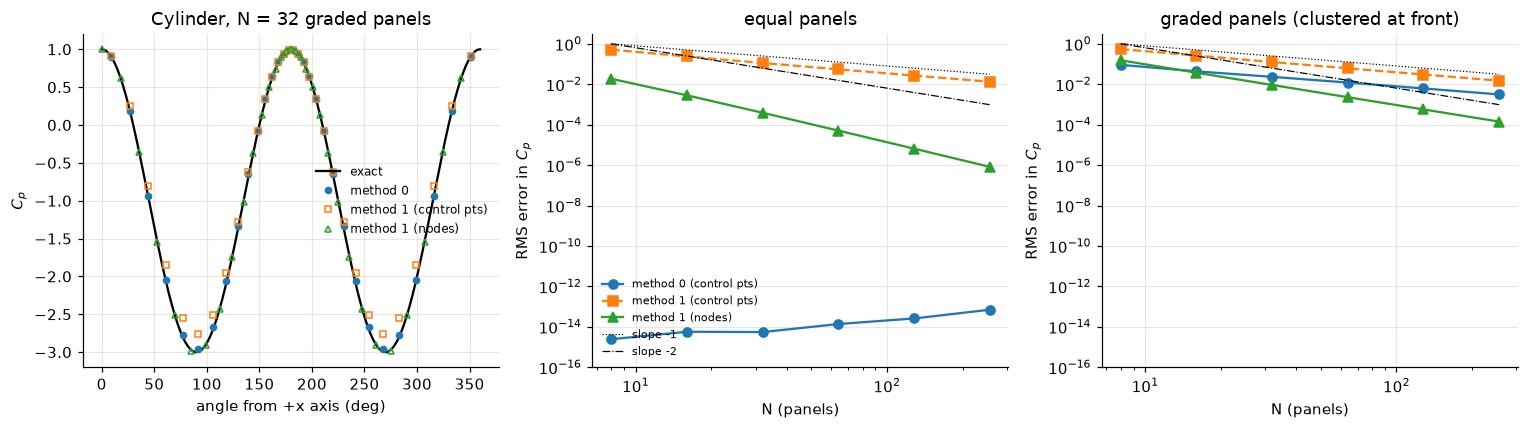

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.0))


N = 32
xb, yb = cylinder_points(N, 1.0, 0.6)
r0 = vortex_panel_method_0(xb, yb, 0.0, closed_body=True)
r1 = vortex_panel_method_1(xb, yb, 0.0, closed_body=True)
phi = np.linspace(0, 2 * np.pi, 400)
ax[0].plot(np.degrees(phi), 1 - 4 * np.sin(phi)**2, "k", lw=1.5, label="exact")
ax[0].plot(np.degrees(np.mod(np.arctan2(r0["yc"], r0["xc"]), 2*np.pi)), r0["Cp"], "o", ms=4, label="method 0")
ax[0].plot(np.degrees(np.mod(np.arctan2(r1["yc"], r1["xc"]), 2*np.pi)), r1["Cp"], "s", ms=4, mfc="none", label="method 1 (control pts)")
ax[0].plot(np.degrees(np.mod(np.arctan2(yb[:-1], xb[:-1]), 2*np.pi)), r1["Cp_nodes"][:-1], "^", ms=4, mfc="none", label="method 1 (nodes)")
ax[0].set(xlabel="angle from +x axis (deg)", ylabel="$C_p$", title="Cylinder, N = 32 graded panels")
ax[0].legend(fontsize=8)


mk = {"method 0 (control pts)": "o-", "method 1 (control pts)": "s--", "method 1 (nodes)": "^-"}
for a, case in zip(ax[1:], cases):
    for lab, st in mk.items():
        e = np.maximum(cyl_err[(case, lab)], 1e-16)
        a.loglog(Ns, e, st, label=lab)
    a.loglog(Ns, 1.0 * (Ns[0] / Ns), "k:", lw=0.8, label="slope -1")
    a.loglog(Ns, 1.0 * (Ns[0] / Ns)**2, "k-.", lw=0.8, label="slope -2")
    a.set(xlabel="N (panels)", ylabel="RMS error in $C_p$", title=case, ylim=(1e-16, 3))
ax[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

**Discussion.**

* **Lift.** Both methods give $C_l=0$ to round-off ($\lesssim10^{-14}$) for equal and graded panels, as they must.
* **Method 0, equal panels: error at round-off for every $N$.** This is *not* evidence of unusual accuracy. For a regular polygon the influence matrices are circulant, so the $\sin\varphi$ mode is an exact eigenvector and the discrete answer coincides with the exact surface speed at the panel mid-points. Symmetric test cases can therefore hide discretisation error — which is why the graded panels were added.
* **Method 0, graded panels:** the error falls with $N$ at observed order **0.96**, i.e. first order, as expected for piecewise-constant strength.
* **Method 1 at the control points:** also first order (observed order **1.02** on both sets) and, at the same $N$, about 4–5 times *larger* than method 0 on the graded set. The nodal strengths are far better: $C_p$ from the nodal $\gamma$ converges at order **2.01** on the graded panels (and about 3 on the equal panels, again helped by symmetry), with errors one to two orders of magnitude below the other curves at $N=256$.
* **Why the two $C_p$ definitions of method 1 differ.** Only the *normal* velocity is forced to vanish at the control points. The tangential velocity just inside the body is not forced to zero, so the outer-side velocity at a mid-point differs from the interpolated sheet strength by an $O(h)$ amount (the velocity at the mid-point was confirmed independently with a brute-force numerical integration of the sheet). The nodal values $V=|\gamma|$ rely on the zero-velocity-inside property and are the natural quantity of the linear scheme. **From here on, $C_p$ for method 1 is taken at the nodes**, and for method 0 at the control points.

## 4. Verification on symmetric and non-symmetric airfoils

Airfoils: **NACA 0012** (symmetric, 12 % thick) and **NACA 4412** (4 % camber at 40 % chord, 12 % thick), both at $\alpha=4^\circ$, chord $c=1$, $V_\infty=1$. The thickness distribution is the standard 4-digit polynomial with the last coefficient set to $-0.1036$ so that the trailing edge is exactly closed.

No analytical solution exists for these airfoils with the *panel* model, so convergence is measured against a **reference solution**: linear panels, $N=1600$, cosine spacing. This measures *self-convergence* (how fast each scheme approaches its own limit); the physical accuracy of that limit is addressed in Sections 5 and 6. $C_p$ errors are RMS values over $0.05\le x/c\le0.95$ on the upper surface (the leading-edge and trailing-edge nodes are excluded from the RMS because the suction peak and the sharp TE are singular-like; the TE node is discussed separately below).

### 4.1 Effect of the number of panels (cosine spacing)

In [30]:
alpha_conv = 4.0
x_grid = 0.5 * (1 - np.cos(np.linspace(np.arccos(1 - 2*0.05), np.arccos(1 - 2*0.95), 60)))   # upper-surface stations, 0.05 <= x/c <= 0.95
ref = {}
for code in ("0012", "4412"):
    r, xb, yb = solve(code, 1600, alpha_conv, 1)
    ref[code] = dict(Cl=r["Cl"], Cp=upper_surface_Cp(r, x_grid, 1))
    print(f"NACA {code}, alpha = {alpha_conv:.0f} deg, reference Cl = {r['Cl']:.5f}")

NACA 0012, alpha = 4 deg, reference Cl = 0.48263
NACA 4412, alpha = 4 deg, reference Cl = 0.99946


In [31]:
Ns_af = np.array([20, 40, 80, 160, 320, 640])
conv = {}   
for code in ("0012", "4412"):
    for method in (0, 1):
        dCl, dCp = [], []
        for N in Ns_af:
            r, xb, yb = solve(code, int(N), alpha_conv, method)
            dCl.append(abs(r["Cl"] - ref[code]["Cl"]))
            dCp.append(np.sqrt(np.mean((upper_surface_Cp(r, x_grid, method) - ref[code]["Cp"])**2)))
        conv[(code, method)] = dict(Cl=np.array(dCl), Cp=np.array(dCp))

print(f"{'N':>5} | " + " | ".join(f"{c} m{m}: dCl      RMS dCp " for c in ('0012', '4412') for m in (0, 1)))
for k, N in enumerate(Ns_af):
    print(f"{N:5d} | " + " | ".join(f"{conv[(c, m)]['Cl'][k]:.2e}  {conv[(c, m)]['Cp'][k]:.2e}  " for c in ("0012", "4412") for m in (0, 1)))

print("\nObserved order of convergence (slope of log error vs log N, N >= 40):")
for (c, m), d in conv.items():
    oCl = -np.polyfit(np.log(Ns_af[1:]), np.log(d["Cl"][1:]), 1)[0]
    oCp = -np.polyfit(np.log(Ns_af[1:]), np.log(d["Cp"][1:]), 1)[0]
    print(f"  NACA {c}, method {m}:  Cl order = {oCl:.2f},  Cp order = {oCp:.2f}")

    N | 0012 m0: dCl      RMS dCp  | 0012 m1: dCl      RMS dCp  | 4412 m0: dCl      RMS dCp  | 4412 m1: dCl      RMS dCp 
   20 | 1.20e-02  2.92e-02   | 3.88e-03  2.29e-02   | 2.01e-02  3.97e-02   | 1.28e-02  1.29e-02  
   40 | 7.25e-03  8.20e-03   | 1.03e-03  5.77e-03   | 1.40e-02  1.13e-02   | 3.17e-03  4.17e-03  
   80 | 3.90e-03  1.20e-03   | 2.59e-04  1.79e-03   | 8.13e-03  2.38e-03   | 5.80e-04  1.40e-03  
  160 | 2.02e-03  3.02e-04   | 6.39e-05  4.94e-04   | 4.16e-03  8.43e-04   | 2.11e-04  5.31e-04  
  320 | 1.03e-03  1.95e-04   | 1.53e-05  1.22e-04   | 2.14e-03  3.87e-04   | 4.60e-05  1.53e-04  
  640 | 5.18e-04  8.72e-05   | 3.31e-06  2.74e-05   | 1.09e-03  2.28e-04   | 5.29e-06  2.67e-05  

Observed order of convergence (slope of log error vs log N, N >= 40):
  NACA 0012, method 0:  Cl order = 0.95,  Cp order = 1.57
  NACA 0012, method 1:  Cl order = 2.06,  Cp order = 1.93
  NACA 4412, method 0:  Cl order = 0.93,  Cp order = 1.39
  NACA 4412, method 1:  Cl order = 2.21,  Cp 

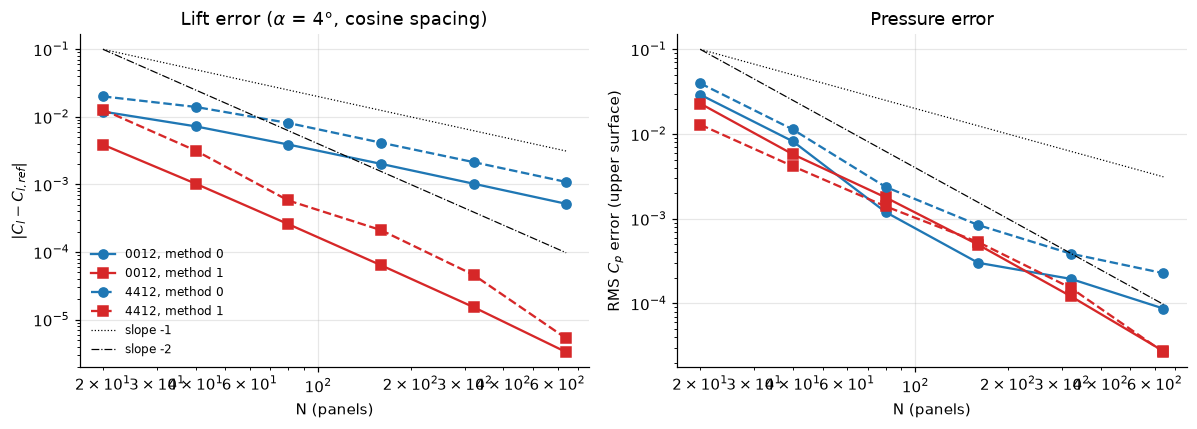

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for code, ls in (("0012", "-"), ("4412", "--")):
    for method, c in ((0, "C0"), (1, "C3")):
        ax[0].loglog(Ns_af, conv[(code, method)]["Cl"], ls, marker="os"[method], color=c, label=f"{code}, method {method}")
        ax[1].loglog(Ns_af, conv[(code, method)]["Cp"], ls, marker="os"[method], color=c, label=f"{code}, method {method}")
for a in ax:
    a.loglog(Ns_af, 0.1 * (Ns_af[0] / Ns_af), "k:", lw=.8, label="slope -1")
    a.loglog(Ns_af, 0.1 * (Ns_af[0] / Ns_af)**2, "k-.", lw=.8, label="slope -2")
    a.set_xlabel("N (panels)")
ax[0].set(ylabel="$|C_l - C_{l,ref}|$", title=r"Lift error ($\alpha$ = 4°, cosine spacing)")
ax[1].set(ylabel="RMS $C_p$ error (upper surface)", title="Pressure error")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Discussion.**

* **Lift converges at the formal order of each scheme:** observed order $\approx0.9$–$0.95$ for constant panels (first order) and $\approx2.1$–$2.2$ for linear panels (second order). On the NACA 4412 at $N=160$ the lift error is $4.2\times10^{-3}$ (method 0) against $2.1\times10^{-4}$ (method 1); at $N=640$ it is $1.1\times10^{-3}$ against $5.3\times10^{-6}$. Linear panels with $N=80$ ($5.8\times10^{-4}$) are already more accurate than constant panels with $N=640$ ($1.1\times10^{-3}$), at one-eighth of the number of unknowns.
* **Pressure error** falls at order $\approx1.4$–$1.6$ (method 0) and $\approx1.8$–$1.9$ (method 1), with comparable levels for the two schemes; method 1 is slightly better at fine resolution. Both are less regular than the lift because a pointwise value is more sensitive than an integral.
* **Camber costs accuracy for constant panels:** at the same $N$ the 4412 lift error of method 0 is about twice that of the 0012 (e.g. $1.1\times10^{-3}$ vs $5.2\times10^{-4}$ at $N=640$), while method 1 is nearly insensitive to camber.
* **Method 0 needs the SVD.** Without removing the saw-tooth mode the lift was still fine but $C_p$ oscillated and did not converge (Section 1.2).

### 4.2 Effect of the distribution of panel lengths

At fixed $N$ three node distributions are compared:

* `uniform`: equal steps in $x$ (panel-length ratio longest/shortest only 1.5);
* `cosine`: clustered at **both** LE and TE (ratio 25 at $N=80$);
* `le_cluster`: clustered at the LE only, long panels towards the TE (ratio 8).

In [33]:
dists = ["uniform", "cosine", "le_cluster"]
Nd = np.array([20, 40, 80, 160, 320])
dist_res = {}                                    
for code in ("0012", "4412"):
    for method in (0, 1):
        for d in dists:
            eCl, eCp = [], []
            for N in Nd:
                r, xb, yb = solve(code, int(N), alpha_conv, method, d)
                eCl.append(abs(r["Cl"] - ref[code]["Cl"]))
                eCp.append(np.sqrt(np.mean((upper_surface_Cp(r, x_grid, method) - ref[code]["Cp"])**2)))
            dist_res[(code, method, d)] = (np.array(eCl), np.array(eCp))

print("Panel-length statistics, N = 80 (NACA 4412):")
for d in dists:
    xb, yb = naca4_points("4412", 80, d)
    S = panel_geometry(xb, yb)[2]
    print(f"  {d:11s}: shortest = {S.min():.5f}, longest = {S.max():.5f}, ratio = {S.max()/S.min():6.1f}")

for method in (0, 1):
    print(f"\nMethod {method}, N = 80, alpha = 4 deg:     |Cl error|   RMS Cp error (0.05<x/c<0.95)")
    for code in ("0012", "4412"):
        for d in dists:
            e = dist_res[(code, method, d)]
            print(f"  NACA {code}, {d:11s}:            {e[0][2]:.2e}      {e[1][2]:.2e}")

print("\nTrailing-edge node, method 1, NACA 4412, alpha = 4 deg: nodal Cp = 1 - gamma^2 at x/c = 1")
for d in dists:
    r, xb, yb = solve("4412", 80, alpha_conv, 1, d)
    print(f"  {d:11s}: Cp(TE node) = {r['Cp_nodes'][0]:8.3f}      (reference N=1600 cosine: {solve('4412', 1600, alpha_conv, 1)[0]['Cp_nodes'][0]:.3f})")

Panel-length statistics, N = 80 (NACA 4412):
  uniform    : shortest = 0.02427, longest = 0.03661, ratio =    1.5
  cosine     : shortest = 0.00157, longest = 0.03978, ratio =   25.3
  le_cluster : shortest = 0.00495, longest = 0.04000, ratio =    8.1

Method 0, N = 80, alpha = 4 deg:     |Cl error|   RMS Cp error (0.05<x/c<0.95)
  NACA 0012, uniform    :            1.32e-03      1.52e-01
  NACA 0012, cosine     :            3.90e-03      1.20e-03
  NACA 0012, le_cluster :            1.47e-03      2.30e-03
  NACA 4412, uniform    :            1.63e-04      1.06e-01
  NACA 4412, cosine     :            8.13e-03      2.38e-03
  NACA 4412, le_cluster :            2.42e-03      1.51e-02

Method 1, N = 80, alpha = 4 deg:     |Cl error|   RMS Cp error (0.05<x/c<0.95)
  NACA 0012, uniform    :            2.82e-03      1.32e-01
  NACA 0012, cosine     :            2.59e-04      1.79e-03
  NACA 0012, le_cluster :            2.39e-03      1.22e-03
  NACA 4412, uniform    :            8.33e-03   

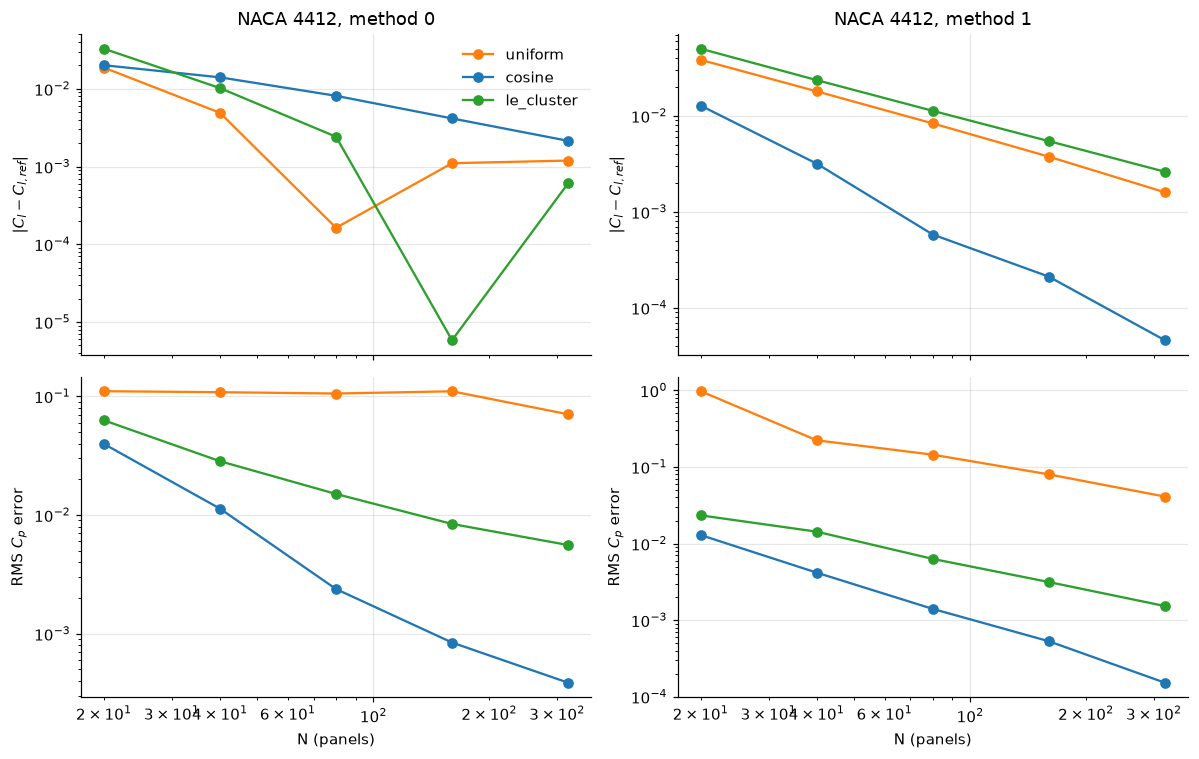

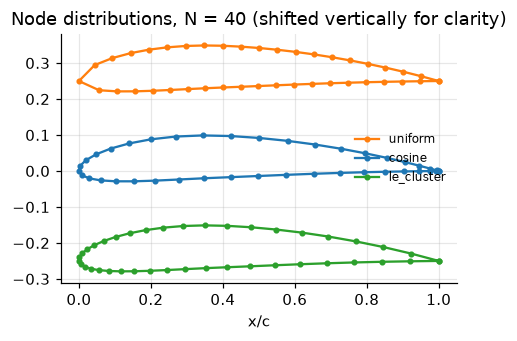

In [34]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for method in (0, 1):
    for d, c in zip(dists, ("C1", "C0", "C2")):
        ax[0, method].loglog(Nd, dist_res[("4412", method, d)][0], "o-", color=c, label=d)
        ax[1, method].loglog(Nd, dist_res[("4412", method, d)][1], "o-", color=c, label=d)
    ax[0, method].set(title=f"NACA 4412, method {method}", ylabel="$|C_l - C_{l,ref}|$")
    ax[1, method].set(xlabel="N (panels)", ylabel="RMS $C_p$ error")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
for d, c, off in zip(dists, ("C1", "C0", "C2"), (0.25, 0.0, -0.25)):
    xb, yb = naca4_points("4412", 40, d)
    ax.plot(xb, yb + off, "o-", ms=3, color=c, label=d)
ax.set(title="Node distributions, N = 40 (shifted vertically for clarity)", xlabel="x/c"); ax.set_aspect("equal"); ax.legend(loc="center right", fontsize=8)
plt.tight_layout(); plt.show()

**Discussion.**

* **Uniform spacing is by far the worst for the pressure distribution.** At $N=80$ the RMS $C_p$ error is about $0.1$–$0.15$ for both methods and both airfoils, roughly **50–100 times larger** than with cosine spacing ($1$–$2\times10^{-3}$), and it falls only slowly with $N$ (for method 0 not at all up to $N=160$). The reason is the nose: the LE radius of the 12 %-thick sections is $r_{LE}=1.1019\,t^2\approx0.016$, while a uniform panel at $N=80$ is $0.024$–$0.037$ long (4412) — longer than the radius it has to follow. The trailing-edge node shows the same problem: with method 1 the nodal $C_p$ at the TE is $-21.7$ for uniform spacing, against $0.95$ (cosine, $N=80$) and the reference value $0.61$.
* **Cosine spacing is the best choice overall**: lowest $C_p$ error for both airfoils and both methods, and for method 1 also the lowest lift error ($2.6\times10^{-4}$ and $5.8\times10^{-4}$ against $2$–$11\times10^{-3}$ for the other two). Caveat: the reference is itself cosine-spaced, which favours that distribution slightly.
* **LE-only clustering is a half measure.** It resolves the nose (the $C_p$ error on the symmetric airfoil is as good as for cosine) but leaves the TE coarse, which is where the Kutta condition is applied; on the cambered airfoil the $C_p$ error is 4–6× that of cosine and the method-1 lift error the largest of the three ($1.1\times10^{-2}$ at $N=80$).
* **Lift of method 0 is not a reliable guide.** Its first-order error changes sign with the distribution, so the uniform grid shows a small lift error for the 4412 ($1.6\times10^{-4}$) by cancellation while its $C_p$ error is $0.106$. The pressure error is the more honest metric.
* **Rule of thumb that follows:** the panel length should be small compared with the local radius of curvature, and neighbouring panels should change in length smoothly (ratios of 25 over the whole airfoil are acceptable with the cosine law because the change is gradual).

## 5. Prediction of airfoil characteristics

Airfoils: **NACA 0012** (symmetric) and **NACA 4412** (cambered); $N=240$ panels, cosine spacing, $\alpha$ from $-4^\circ$ to $12^\circ$. The panel results are compared with thin-airfoil theory ($c_l=2\pi(\alpha-\alpha_{L0})$, where $\alpha_{L0}$ is computed numerically from the camber line), and the pressure-coefficient distributions at $\alpha=0^\circ$ and $6^\circ$ are plotted with the usual inverted $C_p$ axis.

In [35]:
N_pred = 240
alphas = np.arange(-4, 13, 2.0)
pred = {}
for code in ("0012", "4412"):
    for method in (0, 1):
        pred[(code, method)] = np.array([solve(code, N_pred, a, method)[0]["Cl"] for a in alphas])
    p1 = np.polyfit(alphas, pred[(code, 1)], 1)
    aL0_panel = -p1[1] / p1[0]
    print(f"NACA {code}: Cl_alpha = {p1[0]:.4f} /deg = {np.degrees(p1[0]):.3f} /rad   (thin airfoil: 2*pi = 6.283 /rad)")
    print(f"           alpha_L0 (panel) = {aL0_panel:+.3f} deg    alpha_L0 (thin-airfoil theory) = {thin_airfoil_alpha_L0(code):+.3f} deg")
    print(f"           max |Cl_method0 - Cl_method1| over the sweep = {np.max(abs(pred[(code,0)]-pred[(code,1)])):.4f}")

NACA 0012: Cl_alpha = 0.1202 /deg = 6.885 /rad   (thin airfoil: 2*pi = 6.283 /rad)
           alpha_L0 (panel) = +0.000 deg    alpha_L0 (thin-airfoil theory) = +0.000 deg
           max |Cl_method0 - Cl_method1| over the sweep = 0.0041
NACA 4412: Cl_alpha = 0.1195 /deg = 6.849 /rad   (thin airfoil: 2*pi = 6.283 /rad)
           alpha_L0 (panel) = -4.327 deg    alpha_L0 (thin-airfoil theory) = -4.154 deg
           max |Cl_method0 - Cl_method1| over the sweep = 0.0056


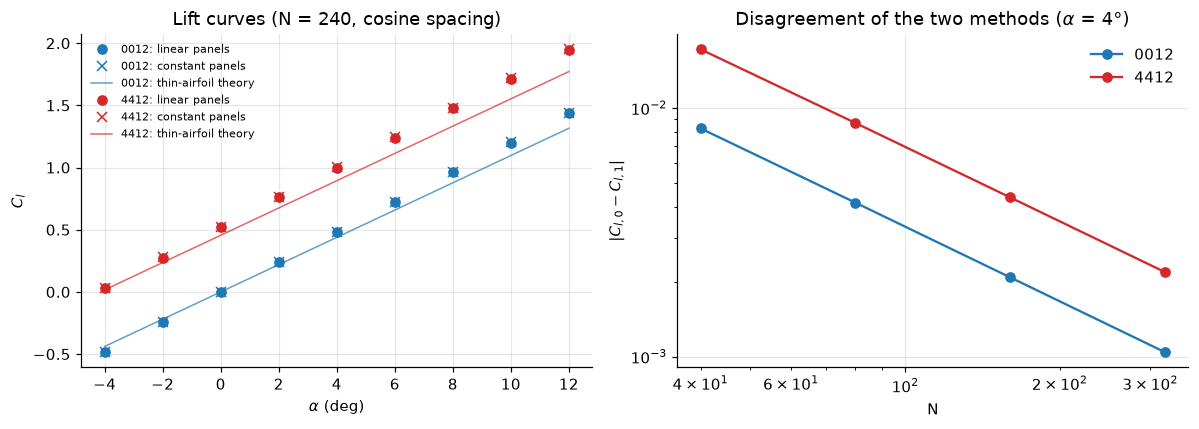

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
a_f = np.linspace(-4, 12, 50)
for code, c in (("0012", "C0"), ("4412", "C3")):
    ax[0].plot(alphas, pred[(code, 1)], "o", color=c, label=f"{code}: linear panels")
    ax[0].plot(alphas, pred[(code, 0)], "x", color=c, ms=6, label=f"{code}: constant panels")
    ax[0].plot(a_f, 2 * np.pi * np.radians(a_f - thin_airfoil_alpha_L0(code)), "-", color=c, lw=1, alpha=.7,
               label=f"{code}: thin-airfoil theory")
ax[0].set(xlabel=r"$\alpha$ (deg)", ylabel="$C_l$", title="Lift curves (N = 240, cosine spacing)")
ax[0].legend(fontsize=7)

# lift: error between methods vs N at alpha = 4
for code, c in (("0012", "C0"), ("4412", "C3")):
    d = [abs(solve(code, int(N), 4.0, 0)[0]["Cl"] - solve(code, int(N), 4.0, 1)[0]["Cl"]) for N in (40, 80, 160, 320)]
    ax[1].loglog((40, 80, 160, 320), d, "o-", color=c, label=code)
ax[1].set(xlabel="N", ylabel=r"$|C_{l,0} - C_{l,1}|$", title=r"Disagreement of the two methods ($\alpha$ = 4°)")
ax[1].legend()
plt.tight_layout(); plt.show()

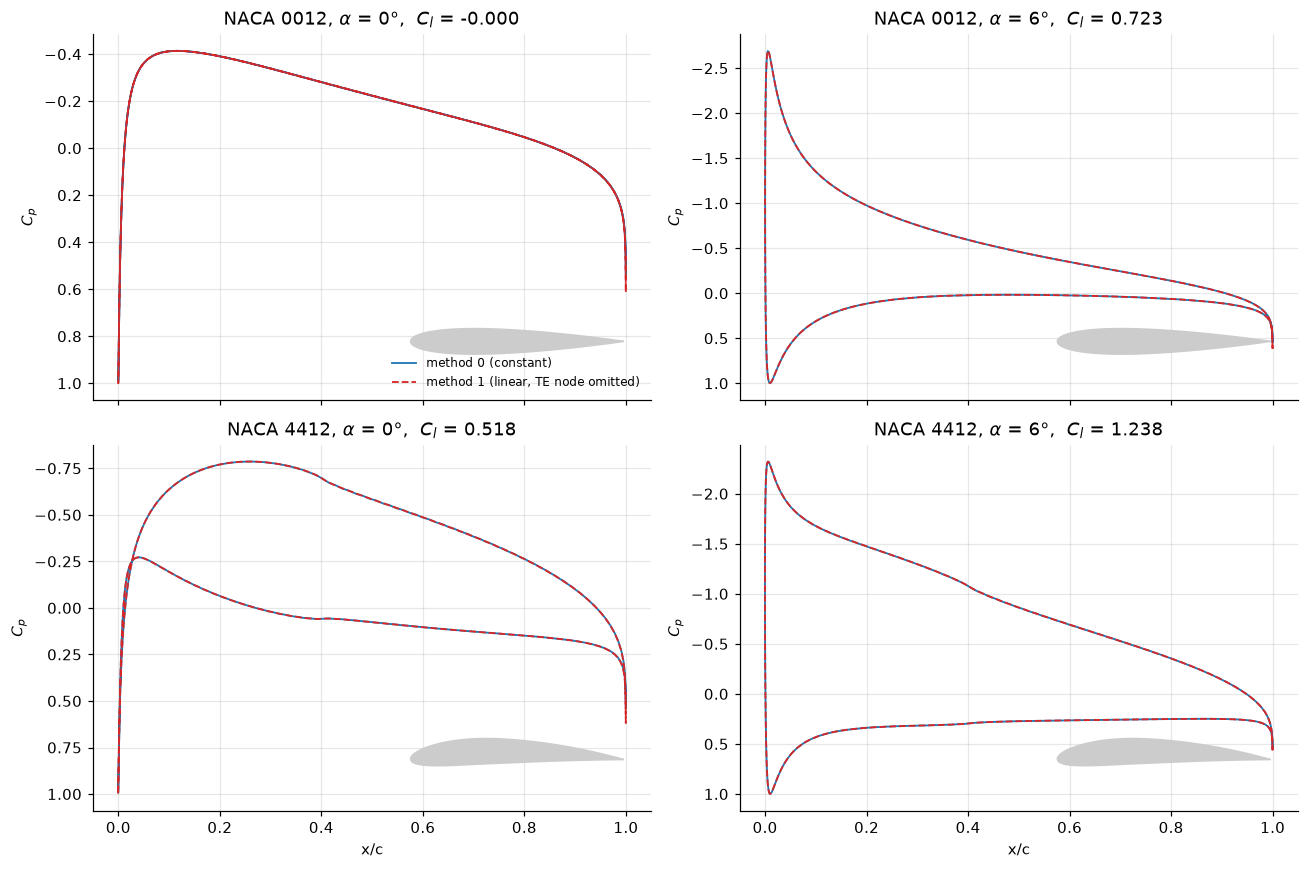

NACA 0012, alpha = 0:  Cp_min = -0.414 at x/c = 0.120 (upper surface),  Cp_max (nodes) = 1.000
NACA 0012, alpha = 6:  Cp_min = -2.693 at x/c = 0.006 (upper surface),  Cp_max (nodes) = 0.996
NACA 4412, alpha = 0:  Cp_min = -0.786 at x/c = 0.257 (upper surface),  Cp_max (nodes) = 1.000
NACA 4412, alpha = 6:  Cp_min = -2.321 at x/c = 0.005 (upper surface),  Cp_max (nodes) = 0.997


In [37]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for row, code in enumerate(("0012", "4412")):
    for col, a in enumerate((0.0, 6.0)):
        r0, xb, yb = solve(code, N_pred, a, 0)
        r1, _, _ = solve(code, N_pred, a, 1)
        ax = axs[row, col]
        ax.plot(r0["xc"], r0["Cp"], "-", lw=1.2, color="C0", label="method 0 (constant)")
        ax.plot(r1["xb"][1:-1], r1["Cp_nodes"][1:-1], "--", lw=1.2, color="C3", label="method 1 (linear, TE node omitted)")
        ax.invert_yaxis()
        ax.set(title=f"NACA {code}, $\\alpha$ = {a:.0f}°,  $C_l$ = {r1['Cl']:.3f}", ylabel="$C_p$")
        if row == 1: ax.set_xlabel("x/c")
        # airfoil sketch inset
        ins = ax.inset_axes([0.55, 0.05, 0.42, 0.22]); ins.fill(xb, yb, color="0.8"); ins.set_aspect("equal"); ins.axis("off")
axs[0, 0].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

# stagnation point and suction peak
for code in ("0012", "4412"):
    for a in (0.0, 6.0):
        r1, xb, yb = solve(code, N_pred, a, 1)
        i_min = np.argmin(r1["Cp_nodes"])
        print(f"NACA {code}, alpha = {a:.0f}:  Cp_min = {r1['Cp_nodes'][i_min]:.3f} at x/c = {xb[i_min]:.3f} "
              f"({'upper' if i_min > len(xb)//2 else 'lower'} surface),  Cp_max (nodes) = {r1['Cp_nodes'].max():.3f}")

**Discussion.**

* **Lift curve.** The curves are straight lines in $\alpha$ (inviscid flow has no stall). The slopes are $6.89$ rad$^{-1}$ (0012) and $6.85$ rad$^{-1}$ (4412), about $9$–$10$ % above the thin-airfoil value $2\pi$. That is consistent with the classical thickness effect, $c_{l\alpha}\approx2\pi(1+0.77\,t/c)=6.86$ rad$^{-1}$ for $t/c=0.12$: the extra lift comes from the thickness of the body, which thin-airfoil theory ignores.
* **Zero-lift angle.** The symmetric airfoil has $\alpha_{L0}=0$ exactly. For the 4412 the panel method gives $-4.33^\circ$ against $-4.15^\circ$ from thin-airfoil theory; camber shifts the whole curve upwards by about $0.52$ in $c_l$ at $\alpha=0$ (method 1: $0.518$ at $N=120$).
* **Agreement of the two methods:** they differ by at most $0.004$ (0012) and $0.006$ (4412) in $c_l$ over the sweep at $N=240$, and the difference decreases with $N$ at the first-order rate of method 0.
* **Pressure distributions.** At $\alpha=0$ the 0012 has identical $C_p$ on both surfaces (no lift), a stagnation point ($C_p=1$) at the LE, and a suction minimum $C_p=-0.41$ at $x/c=0.12$ followed by a gradual pressure recovery to the TE. The cambered airfoil at $\alpha=0$ has a clear upper/lower difference over the whole chord — the area between the curves is the lift — and a deeper minimum, $C_p=-0.79$ at $x/c=0.26$. At $\alpha=6^\circ$ both airfoils develop a sharp leading-edge suction peak, $C_p=-2.69$ (0012) and $-2.32$ (4412) at $x/c\approx0.005$–$0.006$, followed by a strong adverse gradient — in a real flow the place where the boundary layer is most likely to separate.
* **The two methods give practically the same $C_p$** over the whole chord; the curves are indistinguishable at this scale.
* **Trailing-edge node.** For method 1 the single node at the TE is left out of the plots. Its strength is fixed by the Kutta closure $\gamma_1=-\gamma_{N+1}$ rather than by the local flow (for the 0012 at $N=240$, $|\gamma|$ jumps from $0.62$ at the neighbouring node to $0.98$ at the TE node, giving a spurious $C_p=0.04$ there), so it is not a converged pressure value; see also the TE-node values in Section 4.2. A real finite-angle wedge has $C_p\to1$ at the TE.
* **Spurious drag.** Integrating $C_p$ over the surface gives a small non-zero drag (0.0037 at $N=120$), where d'Alembert's paradox requires exactly zero. It is a discretisation error and it decreases with $N$ (about $7\times10^{-4}$ at $N=640$).

## 6. Limitations of the prediction: effect of airfoil thickness

Panel methods solve the *inviscid* equations, so the model itself, not just the numerics, has a range of validity. To expose it, the symmetric family NACA 00$tt$ is solved for $t/c=0.06$ to $0.30$ at $\alpha=5^\circ$ ($N=400$, method 1). Four things are tracked:

1. **Numerical quality** — the change of $c_l$ when $N$ is halved, the disagreement between methods 0 and 1, and the spurious drag from pressure integration. If these stay small, any loss of predictive power is *not* a numerical artefact.
2. **The inviscid lift relative to thin-airfoil theory,** $c_l/(2\pi\alpha)$.
3. **Trailing-edge wedge half-angle**, which controls how well the Kutta condition represents the real flow.
4. **A viscous diagnostic computed from the panel result:** the inviscid surface speed on the upper surface (at $\alpha=0$) is fed to Thwaites' laminar integral method, $\lambda=0.45\,U'/U^6\int_0^sU^5ds$, and laminar separation is flagged where $\lambda<-0.09$. $\lambda$ does not depend on Reynolds number, so the predicted separation position is a Reynolds-number-independent property of the pressure distribution. Only the *trend* is meaningful: in a real flow the boundary layer would usually become turbulent first, but the closer the separation point is to the leading edge, the less room there is for that to rescue the flow.

In [38]:
def thwaites_laminar_separation(res, xb):
    h = len(xb) // 2
    x, y = xb[h:], res["yb"][h:]                      
    U = np.abs(res["gamma"][h:])
    s = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])
    s, U, x = s[1:-1], U[1:-1], x[1:-1]               # drop the stagnation node (singular) and the TE node
    I = np.concatenate([[0.0], np.cumsum(0.5 * (U[1:]**5 + U[:-1]**5) * np.diff(s))]) + U[0]**5 * s[0] / 6
    Uf = np.convolve(np.pad(U, 2, mode="edge"), np.ones(5) / 5, mode="valid")        # light smoothing
    lam = 0.45 * np.gradient(Uf, s) / Uf**6 * I
    k = np.where(lam < -0.09)[0]
    return (x[k[0]] if len(k) else np.nan), x, lam

In [39]:
thick = np.array([6, 9, 12, 15, 18, 21, 24, 30])
a_t = 5.0
rows = []
for tt in thick:
    code = f"00{tt:02d}"
    r1, xb, yb = solve(code, 400, a_t, 1)
    r0, _, _ = solve(code, 400, a_t, 0)
    r_ref, _, _ = solve(code, 1200, a_t, 1)
    
    r_half, _, _ = solve(code, 200, a_t, 1)
    Cl_p, Cd_p = forces_from_Cp(xb, yb, r1["Cp"], a_t)
    r_a0, xb0, _ = solve(code, 400, 0.0, 1)
    xs, _, _ = thwaites_laminar_separation(r_a0, xb0)
    dyt = 5 * (tt / 100) * (0.2969 / 2 - 0.1260 - 2 * 0.3516 + 3 * 0.2843 - 4 * 0.1036)
    te_half = np.degrees(np.arctan(abs(dyt)))
    rows.append(dict(t=tt, Cl=r1["Cl"], Cl_thin=2 * np.pi * np.radians(a_t), Cl_p=Cl_p, Cd=Cd_p,
                     dCl_grid=abs(r_half["Cl"] - r1["Cl"]), dCl_m=abs(r0["Cl"] - r1["Cl"]),
                     xsep=xs, te=te_half, Cpmin=r1["Cp_nodes"].min()))

print(f"alpha = {a_t:.0f} deg, N = 400, method 1, symmetric NACA 00tt sections")
print(f"{'t/c':>5} {'Cl':>7} {'Cl/Cl_thin':>11} {'Cd(press.)':>11} {'|dCl| N:200->400':>17} {'|Cl0-Cl1|':>10} {'TE half-angle':>14} {'Cp_min':>8} {'x_sep/c (alpha=0)':>18}")
for q in rows:
    xs = "attached" if np.isnan(q["xsep"]) else f"{q['xsep']:.3f}"
    print(f"{q['t']/100:5.2f} {q['Cl']:7.4f} {q['Cl']/q['Cl_thin']:11.3f} {q['Cd']:11.5f} {q['dCl_grid']:17.2e} {q['dCl_m']:10.2e} {q['te']:13.1f}° {q['Cpmin']:8.2f} {xs:>18}")

alpha = 5 deg, N = 400, method 1, symmetric NACA 00tt sections
  t/c      Cl  Cl/Cl_thin  Cd(press.)  |dCl| N:200->400  |Cl0-Cl1|  TE half-angle   Cp_min  x_sep/c (alpha=0)
 0.06  0.5752       1.049     0.00132          3.92e-05   1.00e-03           4.2°    -5.08              0.831
 0.09  0.5891       1.074     0.00111          3.90e-05   1.02e-03           6.2°    -2.81              0.727
 0.12  0.6030       1.100     0.00107          3.87e-05   1.04e-03           8.3°    -2.06              0.617
 0.15  0.6170       1.125     0.00110          3.87e-05   1.06e-03          10.3°    -1.78              0.531
 0.18  0.6311       1.151     0.00117          3.87e-05   1.09e-03          12.3°    -1.69              0.469
 0.21  0.6452       1.177     0.00125          3.90e-05   1.11e-03          14.3°    -1.69              0.422
 0.24  0.6594       1.203     0.00135          3.93e-05   1.13e-03          16.2°    -1.75              0.399
 0.30  0.6881       1.255     0.00157          4.04e-05  

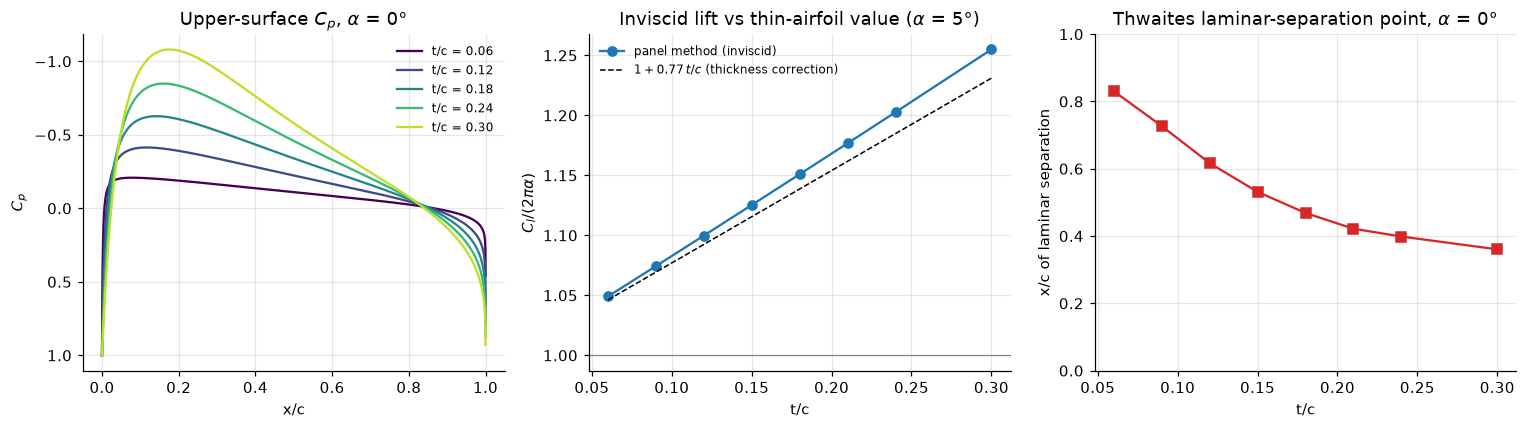

In [40]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for tt, c in zip((6, 12, 18, 24, 30), plt.cm.viridis(np.linspace(0, 0.9, 5))):
    r, xb, yb = solve(f"00{tt:02d}", 400, 0.0, 1)
    h = len(xb) // 2
    ax[0].plot(xb[h:-1], r["Cp_nodes"][h:-1], color=c, label=f"t/c = {tt/100:.2f}")
ax[0].invert_yaxis(); ax[0].set(xlabel="x/c", ylabel="$C_p$", title=r"Upper-surface $C_p$, $\alpha$ = 0°"); ax[0].legend(fontsize=8)

tc = np.array([q["t"] for q in rows]) / 100
ax[1].plot(tc, [q["Cl"] / q["Cl_thin"] for q in rows], "o-", label="panel method (inviscid)")
ax[1].plot(tc, 1 + 0.77 * tc, "k--", lw=1, label=r"$1 + 0.77\,t/c$ (thickness correction)")
ax[1].axhline(1.0, color="0.5", lw=0.8)
ax[1].set(xlabel="t/c", ylabel=r"$C_l / (2\pi\alpha)$", title=r"Inviscid lift vs thin-airfoil value ($\alpha$ = 5°)"); ax[1].legend(fontsize=8)

ax[2].plot(tc, [q["xsep"] for q in rows], "s-", color="C3")
ax[2].set(xlabel="t/c", ylabel="x/c of laminar separation", ylim=(0, 1), title=r"Thwaites laminar-separation point, $\alpha$ = 0°")
plt.tight_layout(); plt.show()

**Discussion.**

* **The numerics do not break down — the physics does.** Across the whole range, halving $N$ changes $c_l$ by only $\approx4\times10^{-5}$, the two methods agree to $\approx10^{-3}$, and the spurious drag stays at $0.001$–$0.0016$. The panel solution is as well converged for a 30 % section as for a 6 % section; what changes is whether the solution describes the real flow.
* **The inviscid lift keeps rising with thickness.** $c_l/(2\pi\alpha)$ increases from $1.05$ ($t/c=0.06$) to $1.26$ ($0.30$), close to the straight line $1+0.77\,t/c$ ($1.05\to1.23$). The panel method therefore predicts that a fatter airfoil produces *more* lift at the same angle of attack, with no limit. The measured lift of real airfoils does not behave like this: viscous displacement and separation reduce the effective camber and lift, and the maximum lift of the symmetric sections peaks at moderate thickness and then falls (see Abbott & von Doenhoff, 1959, for the wind-tunnel data; the reader should compare the trend with those curves).
* **The pressure recovery gets steeper and separation moves forward.** In the left plot the upper-surface $C_p$ at $\alpha=0$ rises more and more abruptly towards the TE as $t/c$ increases. Thwaites' criterion puts laminar separation at $x/c=0.83$ for $t/c=0.06$, $0.62$ for $0.12$, $0.47$ for $0.18$ and $0.36$ for $0.30$ — far upstream of the TE for thick sections, over a long length of the airfoil. A potential-flow model cannot represent any of this: it has no boundary layer, no separated wake and no form drag ($c_d\equiv0$ in theory).
* **The Kutta condition becomes a worse description.** The TE half-angle grows from $4^\circ$ to $20^\circ$. The Kutta condition assumes a thin trailing edge that the flow leaves smoothly; with a blunt wedge the real flow cannot turn the corner and the separated, thick wake changes the effective shape of the body and the circulation.
* **Conclusion.** For thin sections ($t/c\lesssim0.12$) at small $\alpha$ the panel prediction is a good engineering estimate of lift and pressure. As thickness increases, the *method stays numerically accurate but the model becomes less representative of the physical flow*: lift is over-predicted with no stall, drag is zero, and the pressure recovery that the method predicts is steeper than a real boundary layer can survive. Other limits not tested here follow from the same assumptions: large $\alpha$ (stall), high Reynolds-number effects, compressibility near $M\approx0.3$ and above, and unsteady or separated flow.

## 7. Summary, references and acknowledgements

### Summary of results
* Two vortex panel solvers (constant and linear strength) were derived and implemented with closed-form influence coefficients and no loops over panel pairs.
* Cylinder: lift is zero to round-off; method 0 is first-order, method 1 is second-order when $C_p$ is taken from the nodal strengths. Regular-polygon symmetry can make errors vanish identically, so a graded cylinder is needed for an honest test.
* Airfoils: lift converges at order $\approx1$ (constant) and $\approx2$ (linear); cosine spacing is clearly the best panel distribution; uniform spacing fails at the nose and the TE.
* Predictions: $c_{l\alpha}\approx1.09\times2\pi$, $\alpha_{L0}(4412)=-4.3^\circ$, suction peaks and pressure recovery as expected; the two methods agree to $<0.006$ in $c_l$.
* Limits: numerical accuracy is independent of thickness, but the inviscid prediction increasingly misrepresents the physical flow as $t/c$ grows (no stall, no drag, rising lift, separation far forward).

### References
1. J. Katz and A. Plotkin, *Low-Speed Aerodynamics*, 2nd ed., Cambridge University Press, 2001 — Chapters 11 and 12 (vortex panel methods).
2. J. D. Anderson, *Fundamentals of Aerodynamics*, McGraw-Hill — vortex panel method for airfoils (Sec. 4.10) and thin-airfoil theory.
3. A. M. Kuethe and C.-Y. Chow, *Foundations of Aerodynamics*, Wiley, 5th ed., 1998 — linear-strength vortex panels.
4. H. Liu, "Linear Strength Vortex Panel Method for NACA 4412 Airfoil", *IOP Conf. Ser.: Mater. Sci. Eng.* **326**, 012016 (2018), https://iopscience.iop.org/article/10.1088/1757-899X/326/1/012016/pdf — linear-strength formulation (the $C_{n1}, C_{n2}, C_{t1}, C_{t2}$ coefficients correspond to the $(a)/(b)$ coefficients in Section 1.3).
5. I. H. Abbott and A. E. von Doenhoff, *Theory of Wing Sections*, Dover, 1959 — NACA 4-digit geometry and wind-tunnel data.
6. B. Thwaites, "Approximate calculation of the laminar boundary layer", *Aeronautical Quarterly* **1**, 245–280 (1949).
7. AE 611 lecture notes and the assignment handout.

### Acknowledgements
* **Use of AI:** the AI assistant *Claude* (Anthropic) was used to help draft the code structure, the numerical experiments and the text of this report. [EDIT THIS: state what you wrote, checked and changed yourself, e.g. which parts of the derivation you re-derived by hand and which results you reproduced independently.] All results shown here are produced by the code in this notebook.
* **Discussions:** [LIST THE CLASSMATES YOU DISCUSSED WITH, IF ANY — or write "none"].